In [0]:
%python
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType
from pyspark.ml.feature import (
    VectorAssembler,
    StandardScaler,
    StringIndexer,
    OneHotEncoder,
    PCA
)
from pyspark.ml.clustering import KMeans, KMeansModel
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml import Pipeline
 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import warnings
warnings.filterwarnings("ignore")
 
print("Spark version:", spark.version)


Spark version: 4.1.0


In [0]:
%python

DATA_PATH = "/Volumes/workspace/default/fjc_cases/fjc_cases_cleaned.json"

df_raw = (
    spark.read
         .option("multiLine", "false")   # one JSON object per line
         .json(DATA_PATH)
)
 
print(f"Total records: {df_raw.count():,}")
df_raw.printSchema()
df_raw.show(3, truncate=False)


Total records: 117,443
root
 |-- avg_prison_months: double (nullable = true)
 |-- case_duration_days: long (nullable = true)
 |-- case_key: string (nullable = true)
 |-- category: string (nullable = true)
 |-- circuit: string (nullable = true)
 |-- defendant_key: string (nullable = true)
 |-- district: string (nullable = true)
 |-- felony_or_misdemeanor: string (nullable = true)
 |-- file_date: string (nullable = true)
 |-- file_year: long (nullable = true)
 |-- fine_max: double (nullable = true)
 |-- fine_min: double (nullable = true)
 |-- fiscal_year: long (nullable = true)
 |-- offense_code: long (nullable = true)
 |-- offense_description: string (nullable = true)
 |-- offense_level: string (nullable = true)
 |-- prison_max_months: long (nullable = true)
 |-- prison_min_months: long (nullable = true)
 |-- proceeding_code: string (nullable = true)
 |-- proceeding_date: string (nullable = true)
 |-- section_number: double (nullable = true)
 |-- section_text: string (nullable = true)
 

In [0]:
%python

df = df_raw.filter(F.col("fiscal_year").isin(2019, 2025))
 
print("Records per fiscal year:")
df.groupBy("fiscal_year").count().orderBy("fiscal_year").show()
 
print("\nNull counts per numeric column:")
numeric_cols = [
    "case_duration_days",
    "prison_min_months",
    "prison_max_months",
    "fine_min",
    "avg_prison_months",
    "offense_code"
]
df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in numeric_cols
]).show()


Records per fiscal year:
+-----------+-----+
|fiscal_year|count|
+-----------+-----+
|       2019|59371|
|       2025|58072|
+-----------+-----+


Null counts per numeric column:
+------------------+-----------------+-----------------+--------+-----------------+------------+
|case_duration_days|prison_min_months|prison_max_months|fine_min|avg_prison_months|offense_code|
+------------------+-----------------+-----------------+--------+-----------------+------------+
|                 0|             2967|             2967|    6931|             2967|           0|
+------------------+-----------------+-----------------+--------+-----------------+------------+



In [0]:
%python
# CELL 4 — Feature Engineering
# ============================================================
 
# 4a. Encode categorical columns that carry predictability signal
cat_cols = ["offense_level", "felony_or_misdemeanor", "circuit", "sentence_bucket"]
 
indexers = [
    StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep")
    for c in cat_cols
]
encoders = [
    OneHotEncoder(inputCol=f"{c}_idx", outputCol=f"{c}_ohe", dropLast=True)
    for c in cat_cols
]
 
# 4b. Core predictability features
#   • case_duration_days      — how long cases take (scheduling certainty)
#   • avg_prison_months       — central sentencing outcome
#   • prison_min/max_months   — sentencing spread (range = uncertainty)
#   • fine_min                — financial exposure
#   • offense_code            — offense category numeric proxy
#   • sentence_range          — derived: max – min (wider = less predictable)
#   • year_flag               — 2019→0, 2025→1 (temporal shift feature)
 
df = (
    df
    .fillna(0, subset=numeric_cols)
    .withColumn("sentence_range",
                (F.col("prison_max_months") - F.col("prison_min_months")).cast(DoubleType()))
    .withColumn("year_flag",
                F.when(F.col("fiscal_year") == 2025, 1.0).otherwise(0.0))
    .withColumn("log_case_duration",
                F.log1p(F.col("case_duration_days").cast(DoubleType())))
    .withColumn("log_fine_min",
                F.log1p(F.col("fine_min").cast(DoubleType())))
)
 
# Core numeric feature list fed to the assembler
numeric_features = [
    "log_case_duration",      # scheduling predictability
    "avg_prison_months",      # expected sentence
    "sentence_range",         # sentencing uncertainty
    "log_fine_min",           # financial risk
    "year_flag",              # temporal period
]
ohe_features = [f"{c}_ohe" for c in cat_cols]
all_features  = numeric_features + ohe_features
 
print("Feature set:", all_features)
df.select(numeric_features).describe().show()


Feature set: ['log_case_duration', 'avg_prison_months', 'sentence_range', 'log_fine_min', 'year_flag', 'offense_level_ohe', 'felony_or_misdemeanor_ohe', 'circuit_ohe', 'sentence_bucket_ohe']
+-------+-------------------+------------------+------------------+------------------+-------------------+
|summary|  log_case_duration| avg_prison_months|    sentence_range|      log_fine_min|          year_flag|
+-------+-------------------+------------------+------------------+------------------+-------------------+
|  count|             116658|            117443|            117443|            117443|             117443|
|   mean|0.21101423892691712|350.65149902505897|16.189470636819564| 9.127110514381611|0.49446965762114387|
| stddev| 0.8204069722653669|423.93396988692757|29.343720489204212|3.2404885167521518| 0.4999715429532875|
|    min|                0.0|               0.0|             -60.0|               0.0|                0.0|
|    max|  7.653969180478774|             999.0|            

In [0]:
%python
# CELL 5 — Build ML Pipeline (Assemble → Scale → K-Means)
# ============================================================
 
assembler = VectorAssembler(
    inputCols=all_features,
    outputCol="raw_features",
    handleInvalid="skip"
)
 
scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="features",
    withStd=True,
    withMean=True
)
 
# Initial model — we'll tune k with the elbow / silhouette loop below
kmeans_init = KMeans(
    featuresCol="features",
    predictionCol="cluster",
    k=5,
    seed=42,
    maxIter=50,
    initMode="k-means||"
)
 
pipeline = Pipeline(stages=indexers + encoders + [assembler, scaler, kmeans_init])


In [0]:
%python
# CELL 6 — Elbow + Silhouette: Choose Optimal k  (k = 2 … 10)
# ============================================================
 
evaluator = ClusteringEvaluator(
    featuresCol="features",
    predictionCol="cluster",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)
 
# Build just the preprocessing stages once — reuse fitted transform
prep_pipeline = Pipeline(stages=indexers + encoders + [assembler, scaler])
prep_model    = prep_pipeline.fit(df)
df_prepped    = prep_model.transform(df)
df_prepped.createOrReplaceTempView("df_prepped_temp")
df_prepped    = spark.table("df_prepped_temp")
 
k_range      = range(2, 11)
wcss_list    = []   # within-cluster sum of squares (elbow)
silhouette_list = []
 
print("k | WCSS        | Silhouette")
print("-" * 36)
 
for k in k_range:
    km  = KMeans(featuresCol="features", predictionCol="cluster",
                 k=k, seed=42, maxIter=50, initMode="k-means||")
    mdl = km.fit(df_prepped)
    preds = mdl.transform(df_prepped)
 
    wcss = mdl.summary.trainingCost
    sil  = evaluator.evaluate(preds)
 
    wcss_list.append(wcss)
    silhouette_list.append(sil)
    print(f"{k:2d} | {wcss:11.1f} | {sil:.4f}")


k | WCSS        | Silhouette
------------------------------------
 2 |   2372955.6 | 0.5904
 3 |   2646931.4 | 0.2043
 4 |   2142823.9 | 0.1676
 5 |   2057423.3 | 0.1824
 6 |   1914517.2 | 0.2328
 7 |   1535095.7 | 0.3622
 8 |   1509210.4 | 0.3516
 9 |   1339893.0 | 0.3902
10 |   1423796.4 | 0.2892


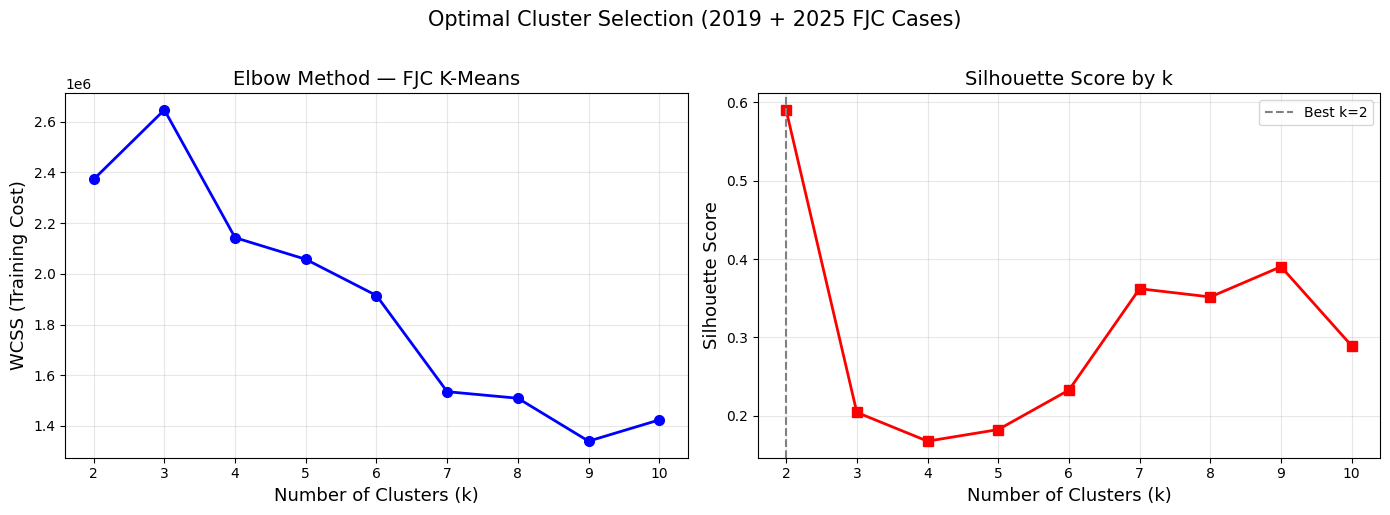


→ Recommended k = 2  (highest silhouette: 0.5904)


In [0]:
%python
# CELL 7 — Plot Elbow & Silhouette (Matplotlib → displayed in Databricks)
# ============================================================
 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
 
ks = list(k_range)
 
# Elbow
ax1.plot(ks, wcss_list, "bo-", linewidth=2, markersize=7)
ax1.set_xlabel("Number of Clusters (k)", fontsize=13)
ax1.set_ylabel("WCSS (Training Cost)", fontsize=13)
ax1.set_title("Elbow Method — FJC K-Means", fontsize=14)
ax1.grid(alpha=0.3)
 
# Silhouette
ax2.plot(ks, silhouette_list, "rs-", linewidth=2, markersize=7)
ax2.set_xlabel("Number of Clusters (k)", fontsize=13)
ax2.set_ylabel("Silhouette Score", fontsize=13)
ax2.set_title("Silhouette Score by k", fontsize=14)
ax2.grid(alpha=0.3)
 
best_k = ks[silhouette_list.index(max(silhouette_list))]
ax2.axvline(best_k, color="gray", linestyle="--", label=f"Best k={best_k}")
ax2.legend()
 
plt.suptitle("Optimal Cluster Selection (2019 + 2025 FJC Cases)", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()
 
print(f"\n→ Recommended k = {best_k}  (highest silhouette: {max(silhouette_list):.4f})")


In [0]:
%python
# CELL 8 — Train Final Model with Best k
# ============================================================
 
BEST_K = best_k   # override manually if desired, e.g. BEST_K = 5
 
km_final = KMeans(
    featuresCol="features",
    predictionCol="cluster",
    k=BEST_K,
    seed=42,
    maxIter=100,
    initMode="k-means||"
)
 
final_model = km_final.fit(df_prepped)
df_clustered = final_model.transform(df_prepped)
df_clustered.createOrReplaceTempView("df_clustered_temp")
df_clustered = spark.table("df_clustered_temp")
 
sil_final = evaluator.evaluate(df_clustered)
print(f"Final model  k={BEST_K}  |  Silhouette = {sil_final:.4f}")
print(f"WCSS = {final_model.summary.trainingCost:,.1f}")


Final model  k=2  |  Silhouette = 0.5904
WCSS = 2,372,955.6


In [0]:
%python
# CELL 9 — Cluster Profile Summary
# ============================================================
 
profile = (
    df_clustered
    .groupBy("cluster", "fiscal_year")
    .agg(
        F.count("*").alias("n_cases"),
        F.round(F.mean("log_case_duration"), 3).alias("avg_log_duration"),
        F.round(F.mean("avg_prison_months"), 2).alias("avg_prison_mo"),
        F.round(F.mean("sentence_range"), 2).alias("avg_sentence_range"),
        F.round(F.mean("log_fine_min"), 3).alias("avg_log_fine"),
        F.round(F.stddev("avg_prison_months"), 2).alias("stddev_prison"),
        F.round(F.mean("case_duration_days"), 1).alias("avg_duration_days")
    )
    .orderBy("cluster", "fiscal_year")
)
 
print("=== Cluster Profiles by Year ===")
profile.show(BEST_K * 2, truncate=False)


=== Cluster Profiles by Year ===
+-------+-----------+-------+----------------+-------------+------------------+------------+-------------+-----------------+
|cluster|fiscal_year|n_cases|avg_log_duration|avg_prison_mo|avg_sentence_range|avg_log_fine|stddev_prison|avg_duration_days|
+-------+-----------+-------+----------------+-------------+------------------+------------+-------------+-----------------+
|0      |2019       |3397   |0.596           |34.44        |-47.42            |6.495       |14.68        |2.5              |
|0      |2025       |9446   |0.211           |19.93        |-23.2             |5.633       |17.54        |0.9              |
|1      |2019       |55682  |0.17            |413.57       |21.79             |9.599       |438.99       |2.2              |
|1      |2025       |48133  |0.231           |363.82       |22.09             |9.454       |422.76       |5.7              |
+-------+-----------+-------+----------------+-------------+------------------+------------+

In [0]:
%python
# CELL 10 — Offense Mix per Cluster
# ============================================================
 
offense_mix = (
    df_clustered
    .groupBy("cluster", "offense_level", "sentence_bucket")
    .count()
    .withColumn("pct", F.round(
        F.col("count") / F.sum("count").over(
            __import__("pyspark.sql.window", fromlist=["Window"])
            .Window.partitionBy("cluster")
        ) * 100, 1
    ))
    .orderBy("cluster", F.desc("count"))
)
 
print("=== Offense & Sentence Mix per Cluster ===")
offense_mix.show(BEST_K * 6, truncate=False)


=== Offense & Sentence Mix per Cluster ===
+-------+-------------------+---------------+-----+----+
|cluster|offense_level      |sentence_bucket|count|pct |
+-------+-------------------+---------------+-----+----+
|0      |Petty offense      |Short          |6467 |50.4|
|0      |Class A Misdemeanor|Medium         |6339 |49.4|
|0      |Class A Misdemeanor|Short          |13   |0.1 |
|0      |Class A Misdemeanor|Long           |10   |0.1 |
|0      |Petty offense      |Long           |8    |0.1 |
|0      |Petty offense      |Medium         |6    |0.0 |
|1      |Felony             |Long           |65475|63.1|
|1      |Felony             |Medium         |38340|36.9|
+-------+-------------------+---------------+-----+----+



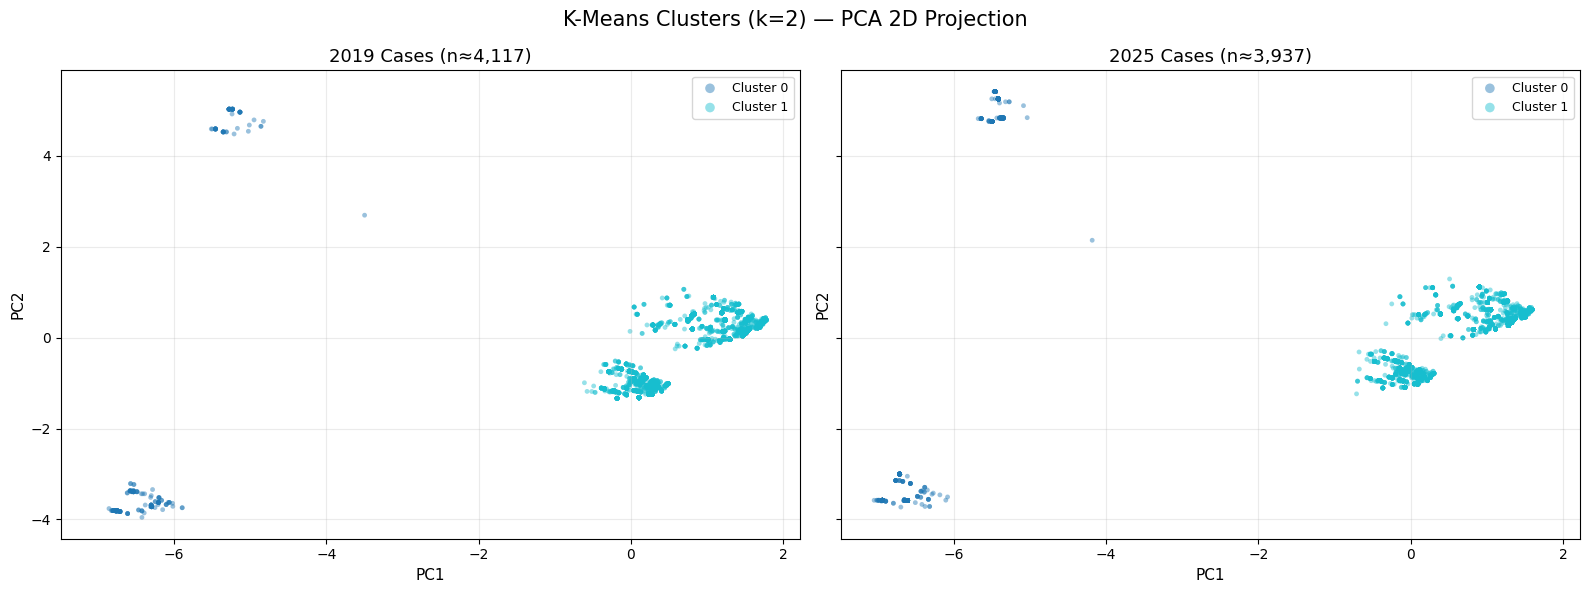

In [0]:
%python
# CELL 12 — 2D PCA Visualization of Clusters
# ============================================================
 
pca = PCA(k=2, inputCol="features", outputCol="pca_coords")
pca_model = pca.fit(df_clustered)
df_pca = pca_model.transform(df_clustered)
 
# Sample for plotting (Databricks: toPandas on a large DF can be slow)
SAMPLE_N = 8000
pdf = (
    df_pca
    .select("pca_coords", "cluster", "fiscal_year")
    .sample(fraction=min(1.0, SAMPLE_N / df_pca.count()), seed=42)
    .toPandas()
)
 
pdf["pc1"] = pdf["pca_coords"].apply(lambda v: float(v[0]))
pdf["pc2"] = pdf["pca_coords"].apply(lambda v: float(v[1]))
 
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
colors = cm.tab10(np.linspace(0, 1, BEST_K))
 
for ax, year in zip(axes, [2019, 2025]):
    sub = pdf[pdf["fiscal_year"] == year]
    for c in range(BEST_K):
        pts = sub[sub["cluster"] == c]
        ax.scatter(pts["pc1"], pts["pc2"],
                   c=[colors[c]], label=f"Cluster {c}",
                   alpha=0.45, s=12, edgecolors="none")
    ax.set_title(f"{year} Cases (n≈{len(sub):,})", fontsize=13)
    ax.set_xlabel("PC1", fontsize=11)
    ax.set_ylabel("PC2", fontsize=11)
    ax.legend(markerscale=2, fontsize=9)
    ax.grid(alpha=0.25)
 
plt.suptitle(f"K-Means Clusters (k={BEST_K}) — PCA 2D Projection", fontsize=15)
plt.tight_layout()
plt.show()


In [0]:
%python
# CELL 13 — Predictability Index per Cluster
# ============================================================
# Composite score: lower sentence_range + lower stddev_prison +
#                  lower case_duration = more predictable (score closer to 1.0)
 
from pyspark.sql.window import Window
 
cluster_stats = (
    df_clustered
    .groupBy("cluster")
    .agg(
        F.mean("sentence_range").alias("mean_range"),
        F.stddev("avg_prison_months").alias("std_sentence"),
        F.mean("case_duration_days").alias("mean_duration"),
        F.count("*").alias("n_cases")
    )
)
 
# Normalize each metric 0–1 then invert (lower raw = higher predictability)
w = Window.orderBy(F.lit(1))   # scalar window for global min/max
 
def min_max_norm_inv(col_name):
    """Returns expression: 1 - (x - min)/(max - min)"""
    return (
        1.0 - (F.col(col_name) - F.min(col_name).over(w))
        / (F.max(col_name).over(w) - F.min(col_name).over(w) + 1e-9)
    )
 
pred_index = (
    cluster_stats
    .withColumn("score_range",    min_max_norm_inv("mean_range"))
    .withColumn("score_std",      min_max_norm_inv("std_sentence"))
    .withColumn("score_duration", min_max_norm_inv("mean_duration"))
    .withColumn("predictability_index",
                F.round(
                    (F.col("score_range") * 0.40 +
                     F.col("score_std")   * 0.40 +
                     F.col("score_duration") * 0.20), 4
                )
    )
    .select("cluster", "n_cases", "mean_range", "std_sentence",
            "mean_duration", "predictability_index")
    .orderBy(F.desc("predictability_index"))
)
 
print("=== Predictability Index by Cluster (1.0 = most predictable) ===")
pred_index.show(truncate=False)


=== Predictability Index by Cluster (1.0 = most predictable) ===
+-------+-------+------------------+------------------+------------------+--------------------+
|cluster|n_cases|mean_range        |std_sentence      |mean_duration     |predictability_index|
+-------+-------+------------------+------------------+------------------+--------------------+
|0      |12843  |-29.60896986685354|18.005252013870205|1.2873160476524177|1.0                 |
|1      |103815 |21.928045080190724|432.25163750274953|3.8258151519529933|0.0                 |
+-------+-------+------------------+------------------+------------------+--------------------+



In [0]:
%python
# CELL 14 — Save Results to Delta (Optional)
# ============================================================
 
OUTPUT_TABLE = "workspace.default.fjc_kmeans_results"
 
(
    df_clustered
    .select(
        "defendant_key", "case_key", "fiscal_year",
        "offense_description", "sentence_bucket",
        "case_duration_days", "avg_prison_months",
        "sentence_range", "fine_min", "cluster"
    )
    .write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(OUTPUT_TABLE)
)
 
print(f"Results written to {OUTPUT_TABLE}")
spark.sql(f"SELECT cluster, COUNT(*) as n FROM {OUTPUT_TABLE} GROUP BY cluster ORDER BY cluster").show()


Results written to workspace.default.fjc_kmeans_results
+-------+------+
|cluster|     n|
+-------+------+
|      0| 12843|
|      1|103815|
+-------+------+



In [0]:
%python
# CELL 15 — Print Human-Readable Cluster Interpretation
# ============================================================
 
print("""
╔══════════════════════════════════════════════════════════════╗
║        FJC K-Means Clustering — Interpretation Guide        ║
╠══════════════════════════════════════════════════════════════╣
║  Features used:                                             ║
║  • log_case_duration   — case scheduling certainty          ║
║  • avg_prison_months   — expected sentence outcome          ║
║  • sentence_range      — spread between min/max (uncertainty)║
║  • log_fine_min        — financial penalty exposure         ║
║  • year_flag           — period indicator (2019=0, 2025=1)  ║
║  • offense/circuit/    — categorical one-hot features       ║
║    sentence_bucket OHE                                      ║
╠══════════════════════════════════════════════════════════════╣
║  Predictability Index weighting:                            ║
║  40% sentence range  +  40% sentence std  +  20% duration  ║
║  Score of 1.0 = most predictable cluster                    ║
╠══════════════════════════════════════════════════════════════╣
║  Next steps:                                                ║
║  • Compare cluster membership 2019 → 2025 (Cell 11)        ║
║  • Use predictability_index to flag high-variance cases     ║
║  • Join OUTPUT_TABLE to case-level data for downstream use  ║
╚══════════════════════════════════════════════════════════════╝
""")



╔══════════════════════════════════════════════════════════════╗
║        FJC K-Means Clustering — Interpretation Guide        ║
╠══════════════════════════════════════════════════════════════╣
║  Features used:                                             ║
║  • log_case_duration   — case scheduling certainty          ║
║  • avg_prison_months   — expected sentence outcome          ║
║  • sentence_range      — spread between min/max (uncertainty)║
║  • log_fine_min        — financial penalty exposure         ║
║  • year_flag           — period indicator (2019=0, 2025=1)  ║
║  • offense/circuit/    — categorical one-hot features       ║
║    sentence_bucket OHE                                      ║
╠══════════════════════════════════════════════════════════════╣
║  Predictability Index weighting:                            ║
║  40% sentence range  +  40% sentence std  +  20% duration  ║
║  Score of 1.0 = most predictable cluster                    ║
╠═══════════════════════════════════